# PMAR demo

**PMAR** (Particle-based Modelling and Analysis for MARine Decision Support) drives [OpenDrift](https://opendrift.github.io/)
to simulate Lagrangian particle trajectories representing different tracers (generic, plastic,
chemical, oil, metal or larvae), then derives:

- **geospatial indicators** (density maps, Pressure Propagation Index or PPI)
- a **connectivity matrix** describing transition probabilities between grid cells,

from those trajectories.

This notebook walks through the core workflow in four steps:

1. **Basic run** — simulate trajectories and compute rasterized indicators/PPI with `.run()`.
2. **Connectivity analysis** — build a connectivity matrix and network with `get_cm` and `get_network`.
3. **Markov-chain prediction** — propagate a distribution forward in time with `predict_with_cm`.
4. **Multi-seeding runs** — repeat the simulation over several seedings and aggregate results with `PMARmulti`.

**Requirements**: run this notebook with the `opendrift` conda environment as the kernel
(it provides OpenDrift, PMAR's other geospatial dependencies, and has `PROJ_LIB` set up
correctly). You'll also need working Copernicus Marine credentials in `~/.netrc` — the
first run streams a couple of days of Mediterranean current data; after that, PMAR's
on-disk cache makes re-running this notebook instant and fully offline.

In [7]:
from shapely.geometry import box
import geopandas as gpd
import matplotlib.pyplot as plt

from pmar.pmar import PMAR
from pmar import plotting
from pmar.utils import list_emodnet_uses, get_emodnet_use
# Small area in the Northern Adriatic Sea, and a single grid resolution, used
# throughout this notebook. Keeping one resolution everywhere means every raster
# we compute lives on exactly the same grid as the connectivity matrix, so they can be
# fed into each other directly with no resampling.
study_area = [12, 43.5, 16, 45.8]  # [xmin, ymin, xmax, ymax]
res = 0.1

## 1. Basic run: `PMAR.run()`

A `PMAR` instance is tied to a spatial domain (one of `'global'`, `'med'`, `'black sea'`,
`'baltic'`) that determines which Copernicus datasets (currents, wind, bathymetry, ...)
are used to force the simulation. All outputs (cached trajectories, rasters, figures) are
written under `basedir`.

`PMAR.run()` bundles the whole single-seeding pipeline into one call: it simulates
particle trajectories (`get_trajectories`), then turns them into gridded rasters in two
complementary ways, both stored together in `p.output`:

- **`get_indicators`** bins the raw (unweighted) particle positions over time into
  summary rasters: `SUM` (total visits per cell), `MAX` (peak concentration), and a
  quantile (`Q90` by default). This answers "where did particles actually go?".
- **`get_ppi`** computes the *Potential Pressure Index*: each particle is weighted by
  the intensity of a human-activity ("use") layer at its *starting* position, so the
  resulting raster answers "how much pressure, originating from this activity, reaches
  each cell?".

`run()` takes:

- `pnum` — number of particles to seed.
- `start_time` — simulation start date, as an ISO `'YYYY-MM-DD'` string.
- `duration` — length of the simulation, in days.
- `seed_within_bounds` — `[xmin, ymin, xmax, ymax]` box to seed particles within (as an
  alternative to `seeding_shapefile`, for seeding from an arbitrary polygon/point/line
  shapefile instead of a rectangle).
- `res` / `study_area` — resolution and spatial bounds for the output rasters.
- `use` / `use_label` — the pressure source for `get_ppi` (see below).

We keep `pnum` and `duration` small here so the demo runs quickly.

Instead of building a `use` layer by hand, we browse real human-activity datasets from the
[EMODnet Human Activities](https://emodnet.ec.europa.eu/en/human-activities) portal with
`list_emodnet_uses(study_area)`, which lists every WFS (vector) / WCS (raster) dataset
("use") available within our study area — its `name` column is exactly what `get_ppi`'s
(and so `run()`'s) `use=` argument expects. We pick `'emodnet__routedensity_allavg'` (a
WCS raster of shipping route density, averaged across all ship types) and pass its name
straight through: a string `use` is recognised (inside `set_weights`) as an EMODnet
dataset identifier and fetched automatically, clipped to `study_area`.

In [8]:
p = PMAR(basedir='pmar_demo_output', loglevel=20)

2026-10-08 13:02:21,583 INFO    pmar:240: initializing pressure generic with opendrift module <class 'opendrift.models.oceandrift.OceanDrift'>


In [9]:
p.study_area = study_area  # reused by several methods below

params = {
    'pnum':1000,
    'start_time':'2021-06-01',
    'duration':10,
    'seed_within_bounds':study_area,
}


In [10]:
list_emodnet_uses(study_area)

                                   name                                                                                   title service output_type
           emodnet__routedensity_allavg                                          Route Density (EMSA) Annual Totals - All types     WCS      raster
            emodnet__routedensity_01avg                                              Route Density (EMSA) Annual Totals - Cargo     WCS      raster
            emodnet__routedensity_02avg                                            Route Density (EMSA) Annual Totals - Fishing     WCS      raster
            emodnet__routedensity_05avg                                              Route Density (EMSA) Annual Totals - Other     WCS      raster
            emodnet__routedensity_03avg                                          Route Density (EMSA) Annual Totals - Passenger     WCS      raster
            emodnet__routedensity_04avg                                             Route Density (EMSA) Annual 

,name,title,service,output_type
0,emodnet__routedensity_allavg,Route Density (EMSA) Annual Totals - All types,WCS,raster
1,emodnet__routedensity_01avg,Route Density (EMSA) Annual Totals - Cargo,WCS,raster
2,emodnet__routedensity_02avg,Route Density (EMSA) Annual Totals - Fishing,WCS,raster
3,emodnet__routedensity_05avg,Route Density (EMSA) Annual Totals - Other,WCS,raster
4,emodnet__routedensity_03avg,Route Density (EMSA) Annual Totals - Passenger,WCS,raster
...,...,...,...,...
139,emodnet:treatmentplants,Treatment Plants,WFS,vector
140,emodnet:unescowhl,UNESCO World Heritage Convention,WFS,vector
141,emodnet:wasteatports,Waste at Ports (m3/tonnes),WFS,vector
142,emodnet:windfarms,Wind Farms (Points),WFS,vector


In [ ]:
use_name = 'emodnet__routedensity_allavg'

In [ ]:
# Individual steps, superseded by run() below:
# p.get_trajectories(**params)
# p.import_trajectories('pmar_demo_output/cachedir/08408fa4e4e37179c6727af9f6bdb25c.nc')
# p.get_indicators(res=res, study_area=study_area)
# p.get_ppi(res=res, study_area=study_area, use=use_name, use_label=use_name)

p.run(**params, res=res, study_area=study_area, use=use_name, use_label=use_name)

2026-10-08 15:18:51,328 INFO    pmar:496: created seeding_shapefile with bounds [12, 43.5, 16, 45.8]
2026-10-08 15:18:51,332 INFO    pmar:505: particle_path exists = False, pmar_demo_output/cachedir/c82b5e2547e37db0a39c55dbc152debe.nc
2026-10-08 15:18:51,450 INFO    pmar:605: adding readers...


ERROR! Session/line number was not unique in database. History logging moved to new session 7048


INFO - 2026-10-08T15:18:51Z - Selected dataset version: "202511"
INFO - 2026-10-08T15:18:51Z - Selected dataset part: "default"
INFO - 2026-10-08T15:18:58Z - Selected dataset version: "202211"
INFO - 2026-10-08T15:18:58Z - Selected dataset part: "default"
INFO - 2026-10-08T15:19:03Z - Selected dataset version: "202211"
INFO - 2026-10-08T15:19:03Z - Selected dataset part: "bathy"
2026-10-08 15:19:04,392 INFO    pmar:627: seeding particles...
2026-10-08 15:19:04,413 INFO    pmar:651: running opendrift...


In [ ]:
p.plot_trajectories(c='age', s=2)

In [ ]:
# use_name is set above; p.duration and get_ppi() are now handled internally by run():
# p.duration = params['duration_days']
# p.get_ppi(res=res, study_area=study_area, use=use_name, use_label=use_name)

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
p.output['SUM'].where(p.output['SUM'] > 0).plot(ax=axs[0])
axs[0].set_title('SUM: particle visits per cell')
p.output['ppi'].where(p.output['ppi'] > 0).plot(ax=axs[1])
axs[1].set_title(f'PPI: pressure from {use_name}')
plt.tight_layout()

## 2. Connectivity analysis: `get_cm` and `get_network`

`get_cm` turns particle transitions into a Markov **transition matrix**: entry `(i, j)`
is the probability that a particle starting in cell `i` at `t=0` ends up in cell `j` at
timestep `t`. We reuse the same `res`/`study_area` as above, so the resulting grid of
cells matches the rasters from section 1 exactly — useful later when we feed one of those
rasters into the Markov prediction in section 3.

> **Note:** `get_cm` also accepts a `buffer` distance, which adds an absorbing
> "outside the tracked domain" cell — useful when the study area has open boundaries and
> you want particles that leave it to be treated as permanently gone rather than
> producing row sums below 1. Not used here, to keep the demo simple.

`get_network` turns the same matrix into a directed `networkx` graph, which we can then
draw. Cell boundaries (from `node_shapes`) give the plot spatial context even without a
full coastline basemap (`show_map=True` currently errors here when combined with the
default weight-based edge colorbar, due to a cartopy/matplotlib axes incompatibility in
`_plot_network` — using `show_map=False` avoids it). With this many cells we skip
`node_names` (per-node text labels) to keep the plot legible — labelling is more useful
on a much smaller network, e.g. `p.get_network(node_names=p.cm_grid['bin_n'].to_dict())`.

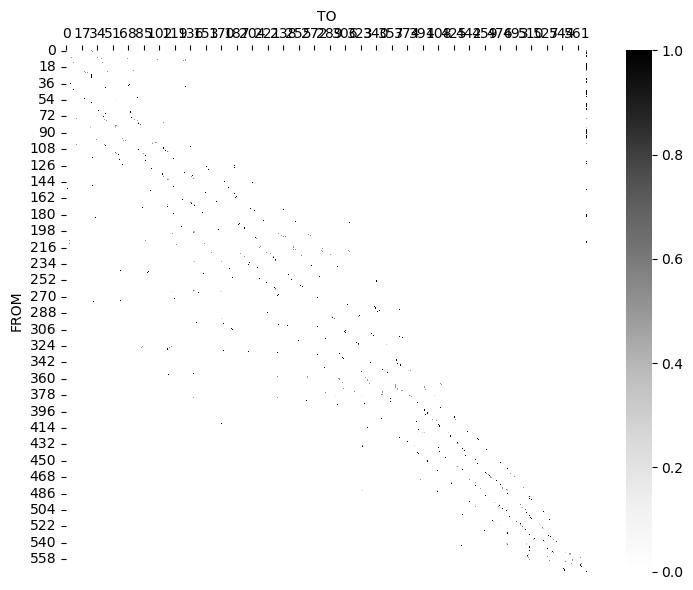

In [8]:
p.get_cm(res=res, study_area=study_area, t=-1, buffer=10)
p.plot_cm()

In [9]:
G = p.get_network()

((<Figure size 700x700 with 2 Axes>, <Axes: >),)

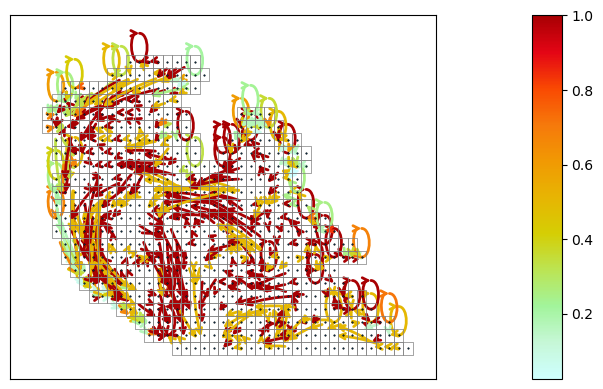

In [10]:
plotting._plot_network(
    G,
    node_shapes=p.cm_grid[:-1],
    show_map=False,
    node_size=1,
 #   rescale_edge=0.05
),  

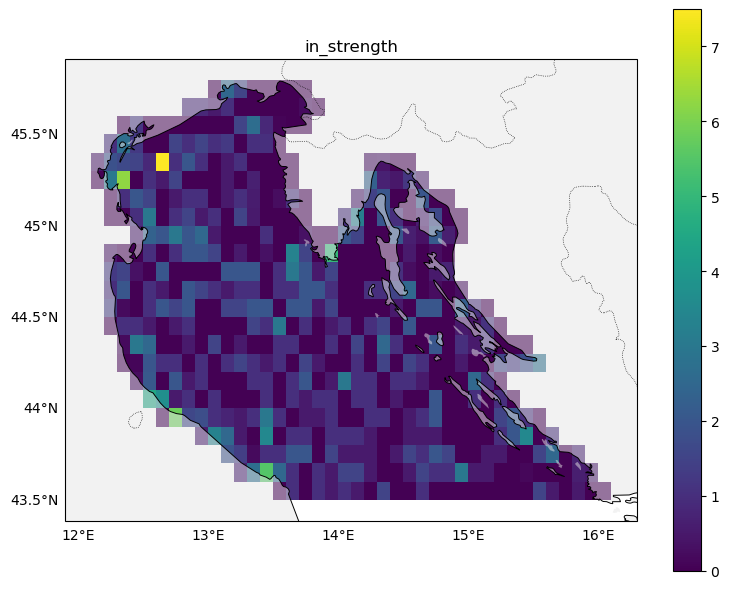

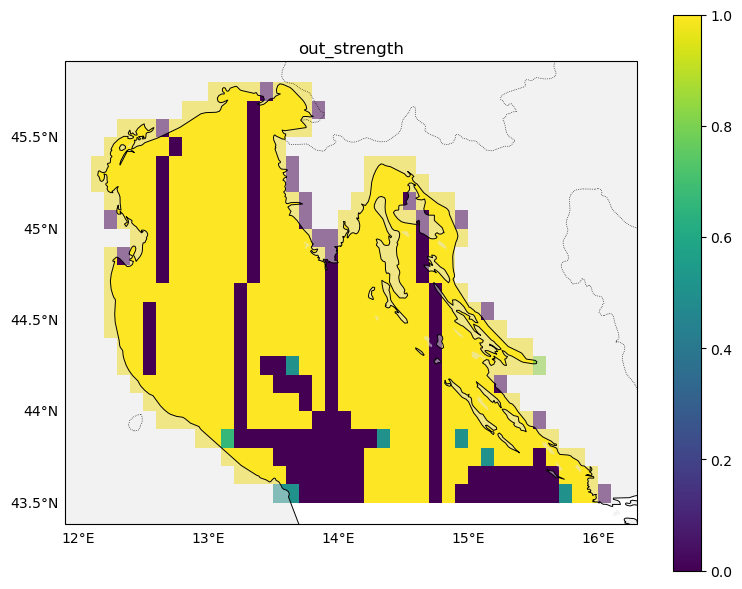

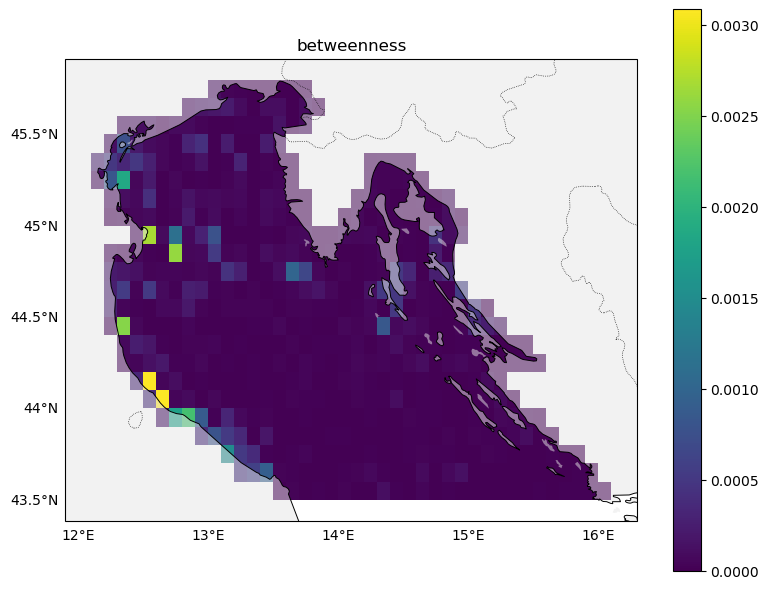

In [11]:
cdf = p.connectivity_analysis(plot=True)

## 3. Markov-chain prediction: `predict_with_cm`

Given a starting distribution (occupancy/probability per cell) and the transition matrix
`cm`, `predict_with_cm` propagates it forward `k` Markov steps: `v -> v @ cm^k`. Each step
corresponds to the same `t` used when the matrix was built (here, the full 2-day
transition from the basic run).

We reuse the `SUM` raster from section 1 as the starting distribution. `predict_with_cm`
reprojects its input onto whichever grid is currently set on `p.grid` — since we've used
the same `res`/`study_area` throughout, that's the same grid `SUM` was already computed
on, so this reprojection is effectively a no-op (important: feeding in a raster from a
*different* resolution than the connectivity matrix would silently distort results, since
reprojecting an additive quantity like a particle count onto a coarser grid via
nearest-neighbour resampling does not sum the finer cells it replaces).

2026-10-07 13:56:09,767 WARNING pmar:1736: initial_condition and cm dimensions do not match


(571,)
(571,)
148013.27393458676
Starting mass: 233706.0
Predicted mass: 148013.27393458676 (may be <= starting mass: some probability can leak outside the tracked domain)


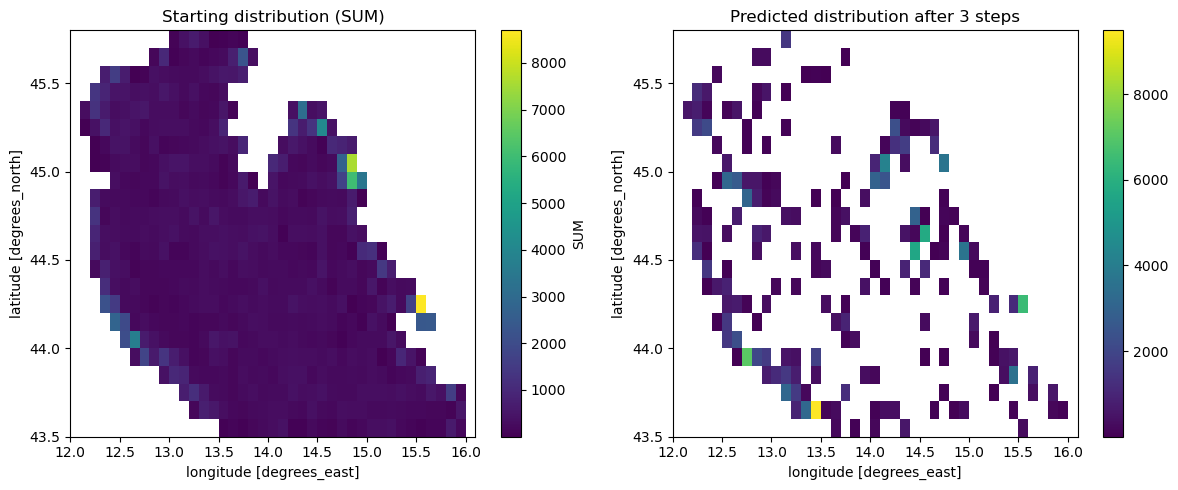

In [16]:
pred = p.predict_with_cm(p.output['SUM'], k=3)

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
p.output['SUM'].where(p.output['SUM'] > 0).plot(ax=axs[0])
axs[0].set_title('Starting distribution (SUM)')
pred.where(pred > 0).plot(ax=axs[1])
axs[1].set_title('Predicted distribution after 3 steps')
plt.tight_layout()

print('Starting mass:', float(p.output['SUM'].sum()))
print('Predicted mass:', float(pred.sum()), '(may be <= starting mass: some probability can leak outside the tracked domain)')

## 4. Multi-seeding runs: `PMARmulti`

Everything so far used a single release of particles at one point in time. `PMARmulti`
repeats the same trajectory simulation across several seedings (offset by `tshift` days,
via `seedings`) and aggregates the results — useful for building indicators/connectivity
matrices that reflect typical conditions rather than being tied to one specific release
date.

Its API mirrors `PMAR`'s: `get_trajectories` takes the same parameters plus `seedings`/
`tshift`, and builds `self.ds` with an extra `seeding` dimension (one simulation per
seeding, concatenated together). `get_cm()` runs the single-seeding connectivity-matrix
calculation independently for each seeding and returns the average across all of them.

2026-10-08 09:16:17,371 INFO    pmar:240: initializing pressure generic with opendrift module <class 'opendrift.models.oceandrift.OceanDrift'>
2026-10-08 09:16:17,374 INFO    pmar:2138: Starting rep #0 with start_time = 2021-06-01, end_time: None, and duration: 1
2026-10-08 09:16:17,379 INFO    pmar:165: auto-selected spatial_domain(s): ['med']
2026-10-08 09:16:17,380 INFO    pmar:488: auto-selected spatial_domain: auto: med
2026-10-08 09:16:17,427 INFO    pmar:496: created seeding_shapefile with bounds [12, 43.5, 16, 45.8]
2026-10-08 09:16:17,430 INFO    pmar:505: particle_path exists = False, pmar_demo_output/cachedir/b6dc33381333a6f50d5b6f17ccb5e218.nc
2026-10-08 09:16:17,734 INFO    pmar:605: adding readers...
INFO - 2026-10-08T09:16:18Z - Selected dataset version: "202511"
INFO - 2026-10-08T09:16:18Z - Selected dataset part: "default"
INFO - 2026-10-08T09:16:21Z - Selected dataset version: "202211"
INFO - 2026-10-08T09:16:21Z - Selected dataset part: "default"
INFO - 2026-10-08T09

string


INFO - 2026-10-08T09:16:51Z - Selected dataset version: "202511"
INFO - 2026-10-08T09:16:51Z - Selected dataset part: "default"
INFO - 2026-10-08T09:16:54Z - Selected dataset version: "202211"
INFO - 2026-10-08T09:16:54Z - Selected dataset part: "default"
INFO - 2026-10-08T09:16:59Z - Selected dataset version: "202211"
INFO - 2026-10-08T09:16:59Z - Selected dataset part: "bathy"
2026-10-08 09:16:59,956 INFO    pmar:627: seeding particles...
2026-10-08 09:16:59,969 INFO    pmar:651: running opendrift...
2026-10-08 09:17:15,996 INFO    pmar:666: total simulation runtime 0:00:25.074170
2026-10-08 09:17:16,010 INFO    pmar:680: particle simulation lat = (100, 25), lon=(100, 25), time=(25,)
2026-10-08 09:17:16,012 INFO    pmar:681: done. NetCDF file 'pmar_demo_output/cachedir/05cd805f070f5da0f752058a72feebd2.nc' created successfully.
2026-10-08 09:17:16,013 INFO    pmar:2143: Done with rep #1.
2026-10-08 09:17:16,015 INFO    pmar:2138: Starting rep #2 with start_time = 2021-06-03, end_time:

string


INFO - 2026-10-08T09:17:16Z - Selected dataset version: "202511"
INFO - 2026-10-08T09:17:16Z - Selected dataset part: "default"
INFO - 2026-10-08T09:17:19Z - Selected dataset version: "202211"
INFO - 2026-10-08T09:17:19Z - Selected dataset part: "default"
INFO - 2026-10-08T09:17:24Z - Selected dataset version: "202211"
INFO - 2026-10-08T09:17:24Z - Selected dataset part: "bathy"
2026-10-08 09:17:25,193 INFO    pmar:627: seeding particles...
2026-10-08 09:17:25,211 INFO    pmar:651: running opendrift...
2026-10-08 09:17:41,159 INFO    pmar:666: total simulation runtime 0:00:25.142619
2026-10-08 09:17:41,173 INFO    pmar:680: particle simulation lat = (100, 25), lon=(100, 25), time=(25,)
2026-10-08 09:17:41,174 INFO    pmar:681: done. NetCDF file 'pmar_demo_output/cachedir/59401e8b9df64a9f3d23477c9fceeaa3.nc' created successfully.
2026-10-08 09:17:41,175 INFO    pmar:2143: Done with rep #2.


string
list
trajectory dataset dims: {'seeding': 3, 'trajectory': 100, 'time': 73}


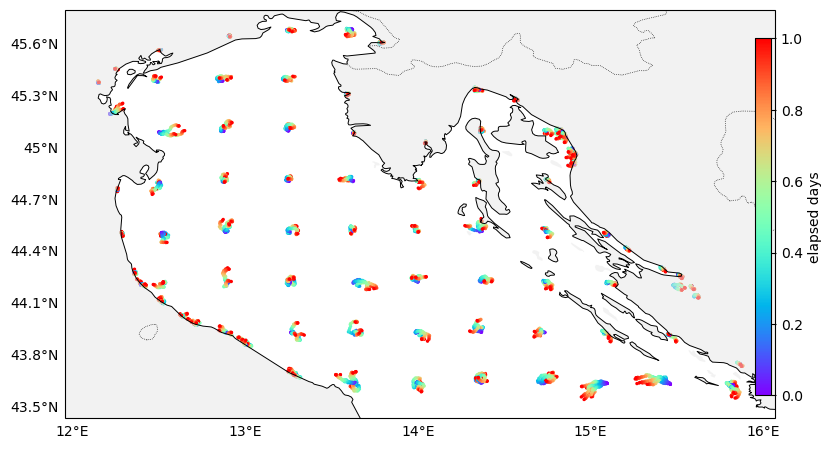

In [3]:
from pmar.pmar import PMARmulti

pm = PMARmulti(basedir='pmar_demo_output', loglevel=20)
pm.study_area = study_area

pm.get_trajectories(
    pnum=100,
    start_time='2021-06-01',
    duration_days=1,
    seedings=3,
    tshift=1,
    seed_within_bounds=study_area,
)

pm.plot_trajectories(c='age', s=2)
print('trajectory dataset dims:', dict(pm.ds.sizes))

In [6]:
pm.ds

<xarray.Dataset> Size: 527kB
Dimensions:        (seeding: 3, trajectory: 100, time: 73)
Coordinates:
  * trajectory     (trajectory) int32 400B 0 1 2 3 4 5 6 ... 94 95 96 97 98 99
  * time           (time) datetime64[ns] 584B 2021-06-01 ... 2021-06-04
Dimensions without coordinates: seeding
Data variables:
    lon            (seeding, trajectory, time) float32 88kB dask.array<chunksize=(1, 100, 25), meta=np.ndarray>
    lat            (seeding, trajectory, time) float32 88kB dask.array<chunksize=(1, 100, 25), meta=np.ndarray>
    z              (seeding, trajectory, time) float32 88kB dask.array<chunksize=(1, 100, 25), meta=np.ndarray>
    age_seconds    (seeding, trajectory, time) float32 88kB dask.array<chunksize=(1, 100, 25), meta=np.ndarray>
    origin_marker  (seeding, trajectory, time) float64 175kB dask.array<chunksize=(1, 100, 25), meta=np.ndarray>
Attributes: (12/123)
    Conventions:                                                           CF...
    standard_name_vocabulary:                                              CF...
    featureType:                                                           tr...
    title:                                                                 Op...
    summary:                                                               Ou...
    keywords:                                                              tr...
    ...                                                                    ...
    geospatial_lon_units:                                                  de...
    geospatial_lon_resolution:                                             point
    runtime:                                                               0:...
    geospatial_vertical_min:                                               -4...
    geospatial_vertical_max:                                               -0...
    geospatial_vertical_positive:                                          up

2026-10-08 09:18:12,709 INFO    pmar:2375: Calculating average cm out of 3 particle files.
2026-10-08 09:18:12,731 INFO    pmar:240: initializing pressure generic with opendrift module <class 'opendrift.models.oceandrift.OceanDrift'>


ds


2026-10-08 09:18:20,491 INFO    pmar:2397: Done calculating cm for particle file 0.
2026-10-08 09:18:20,496 INFO    pmar:2375: Calculating average cm out of 3 particle files.
2026-10-08 09:18:20,509 INFO    pmar:240: initializing pressure generic with opendrift module <class 'opendrift.models.oceandrift.OceanDrift'>


ds


2026-10-08 09:18:28,537 INFO    pmar:2397: Done calculating cm for particle file 1.
2026-10-08 09:18:28,540 INFO    pmar:2375: Calculating average cm out of 3 particle files.
2026-10-08 09:18:28,552 INFO    pmar:240: initializing pressure generic with opendrift module <class 'opendrift.models.oceandrift.OceanDrift'>


ds


2026-10-08 09:18:36,317 INFO    pmar:2397: Done calculating cm for particle file 2.


list


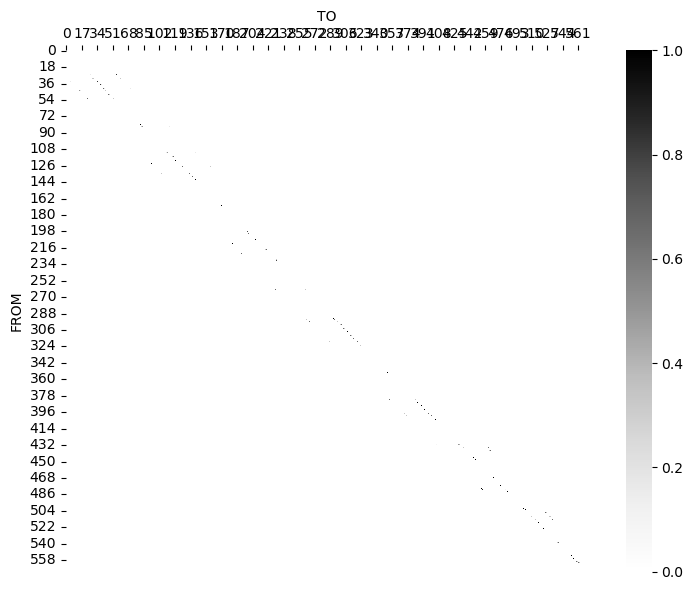

In [4]:
pm.get_cm(res=res, study_area=study_area, t0=0, t1=-1)
pm.plot_cm()

## Where to go next

This notebook covered the core single-seeding workflow. A few other things PMAR can do:

- **Other pressure types**: pass `pressure='plastic'|'chemical'|'oil'|'metal'|'larvae'`
  to `PMAR(...)` instead of the default `'generic'` to use OpenDrift's specialized
  modules (e.g. `chemical_compound=` for `'chemical'`/`'metal'`).
- **Dispersal distance**: `p.dispersal_distance()` computes the probability-weighted
  mean distance travelled from each cell, directly from the connectivity matrix.
- **`PMARmulti.run(...)`** bundles `get_trajectories` + `get_ppi` + `get_indicators` into
  a single call for the multi-seeding case too, for when you don't need the intermediate
  steps shown in section 4.